# Modern Makine Öğrenmesi Mimarisi Geliştirme
## Hafta 3 — Modelleme Temelleri, Decision Tree ve Bagging

> **Ana fikir:** Bir modeli yalnızca kütüphaneden çağırmak yerine, hangi amaç fonksiyonunu neden optimize ettiğini ve hatayı nasıl azalttığını anlayacağız.

**Ders süresi:** 60 dk teori + 60 dk uygulama  
**Bu haftanın sınırı:** Regresyon ve sınıflandırmanın çalışma mantığı → tree → bagging. Boosting ve bagging–boosting karşılaştırmasını gelecek haftaya bırakıyorum.

### Bu dersin sonunda birlikte
- Regresyon ve sınıflandırma problemlerini ayırabileceğiz.
- Lineer ve lojistik regresyonun nasıl öğrendiğini adım adım açıklayabileceğiz.
- Bir ağacın aday split'leri nasıl karşılaştırdığını açıklayabileceğiz.
- Bootstrap, çoğunluk oyu ve bagging'in varyans azaltma etkisini açıklayabileceğiz.
- Decision Tree, Bagging, Random Forest ve Extra Trees modellerini karşılaştırabileceğiz.
- Önceki haftanın churn verisini leakage oluşturmadan modelleyebileceğiz.

### Akış
1. Sınıflandırma ve regresyon temeli
2. Lineer regresyonun adım adım çalışma mantığı
3. Lojistik regresyonun adım adım çalışma mantığı
4. Unsupervised learning'e kısa giriş
5. Decision Tree'nin adım adım çalışma mantığı
6. Bagging'in çalışma mantığı ve modelleri
7. Churn verisi üzerinde model karşılaştırması
8. LazyPredict ile hızlı benchmark


## 1. Önce problem türünü doğru seçelim

| Problem | Çıktı | Örnek |
|---|---|---|
| Regresyon | Sürekli sayı | Aylık gelir, talep, müşteri ömrü |
| Binary classification | İki sınıf / olasılık | Churn eder–etmez |
| Multiclass classification | Birden fazla sınıftan biri | Arıza tipi |
| Multilabel classification | Aynı anda birden fazla etiket | İçerik etiketleri |
| Clustering | Etiketsiz gruplar | Davranış segmentleri |
| Anomaly detection | Normallikten sapma | Şüpheli işlem |
| Forecasting | Zaman indeksli gelecek değer | Günlük çağrı adedi |
| Ranking | Sıralı liste | Yatırım veya teklif önceliği |

Bu hafta supervised learning tarafında regresyon ve binary classification'a odaklanacağım. Unsupervised learning'i ise yanlış problem seçimini engelleyecek kadar çerçeveleyeceğim.

## 2. Sınıflandırma nasıl çalışır?

Bir sınıflandırma modelinin yaptığı işi dört adımda düşünebiliriz:

1. Her satırdaki feature'ları alır: kontrat türü, kullanım değişimi, şikâyet sayısı gibi.
2. Eğitim verisindeki `churn=0` ve `churn=1` örnekleri arasındaki örüntüyü öğrenir.
3. Yeni müşteri için `churn=1` sınıfına ait olma skoru veya olasılığı üretir.
4. Seçtiğimiz eşikle bu olasılığı iş kararına dönüştürür.

Örneğin model `0.72` churn olasılığı üretebilir. Bu henüz müşteriye kampanya gönderileceği anlamına gelmez. Eşik, ulaşılabilecek müşteri sayısı, teklif maliyeti ve kaç churn müşterisini yakalamak istediğimizle birlikte seçilir.

> **Olasılık üretmek**, **sınıf kararı vermek** ve **iş aksiyonu almak** üç ayrı aşamadır.

### Sınıflandırma: veriden karara

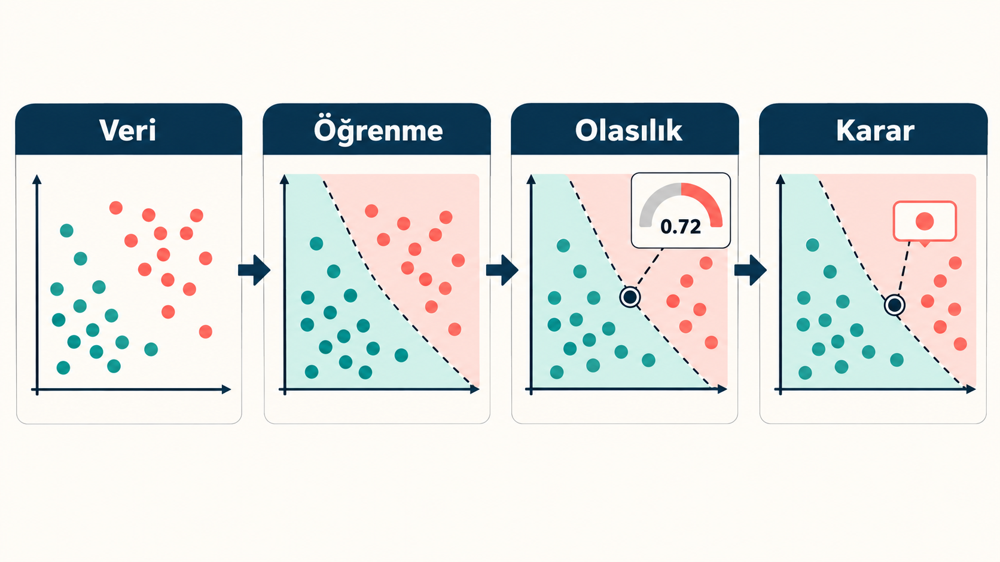

*Model önce sınıflar arasındaki ayrımı öğrenir, yeni gözlem için olasılık üretir ve seçilen eşikle karar verir.*

### Confusion matrix ve temel metrikler

Tahminleri dört gruba ayırırım:

- **True Positive:** Churn edecek dedim ve gerçekten etti.
- **False Positive:** Churn edecek dedim ama etmedi; gereksiz aksiyon maliyeti oluşabilir.
- **False Negative:** Churn etmeyecek dedim ama etti; kurtarılabilecek müşteriyi kaçırdım.
- **True Negative:** Churn etmeyecek dedim ve etmedi.

**Precision**, ulaştığım müşterilerin ne kadarının gerçekten churn ettiğini; **recall**, gerçek churn müşterilerinin ne kadarını yakaladığımı anlatır. **F1** ikisi arasında denge arar. Accuracy ise churn az görüldüğünde yanıltıcı olabilir: herkese `0` diyen model yüksek accuracy alabilir.

## 3. Lineer regresyon nasıl çalışır?

Lineer regresyon sürekli bir değer tahmin eder: gelir, talep veya müşteri ömrü gibi. Çalışma mantığını adım adım düşünelim:

1. Model her feature için başlangıçta bir katsayı belirler.
2. Her satırda feature değerlerini katsayılarla çarpıp toplar ve bir tahmin üretir.
3. Tahmin ile gerçek değer arasındaki farkı hesaplar.
4. Büyük hataların daha fazla etkili olması için hataların karesini kullanır.
5. Katsayıları, toplam hatayı azaltacak yöne doğru günceller.
6. Hata yeterince azalana veya belirlenen iterasyon tamamlanana kadar bu işlemi tekrarlar.

Bir katsayının pozitif olması feature arttıkça tahminin yükselme eğiliminde olduğunu, negatif olması düşme eğiliminde olduğunu gösterir. Bu ilişki tek başına nedensellik kanıtlamaz.

### Lineer regresyon: çizgiyi hataya göre düzeltmek

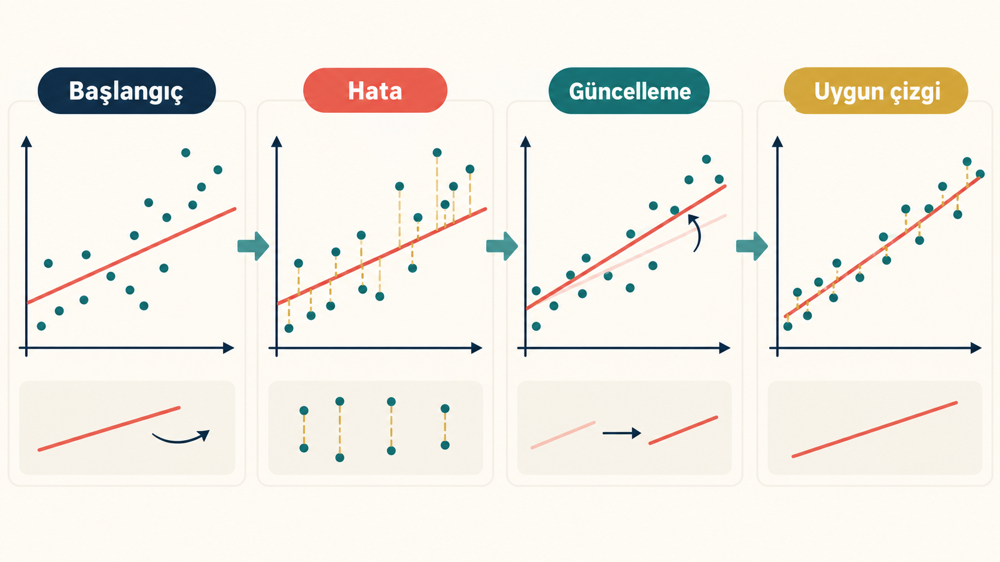

*Başlangıç çizgisi tahmin üretir; residual'lar ölçülür ve çizgi toplam hatayı azaltacak yönde güncellenir.*

## 4. Model neyi azaltmaya çalışır? Loss ve Cost Function

Modelin yalnızca hata yaptığını bilmesi yetmez; farklı parametreleri karşılaştırabileceği tek bir sayıya ihtiyacı vardır. Bu sayıyı **cost function** üretir.

Adım adım düşünelim:

1. Model mevcut parametrelerle her satır için tahmin üretir.
2. Her tahmin gerçek değerle karşılaştırılır.
3. Tek bir satırdaki hatanın cezasına **loss** deriz.
4. Bütün satırların loss değerleri birleştirilerek tek bir **cost** değeri oluşturulur.
5. Düşük cost, modelin eğitim verisine genel olarak daha iyi uyduğunu gösterir.
6. Gradient descent parametreleri cost değerini azaltacak yönde günceller.
7. Yeni tahminler ve yeni cost hesaplanır; süreç tekrar eder.

### Loss ile cost arasındaki fark
- **Loss:** Tek bir gözlemde ne kadar hata yaptım?
- **Cost:** Veri setinin genelinde ne kadar hata yaptım?

Seçtiğimiz cost function modelin neyi iyi sayacağını belirler. Regresyonda büyük sayısal hataları cezalandırmak için çoğunlukla squared error/MSE; sınıflandırmada olasılıkların güven düzeyini değerlendirmek için log-loss kullanırız. Decision Tree ise gradient descent kullanmaz; split seçerken Gini, entropy veya hata azalması gibi ayrı kriterlerden yararlanır.

### Cost function: model hatasını tek bir sinyale dönüştürmek

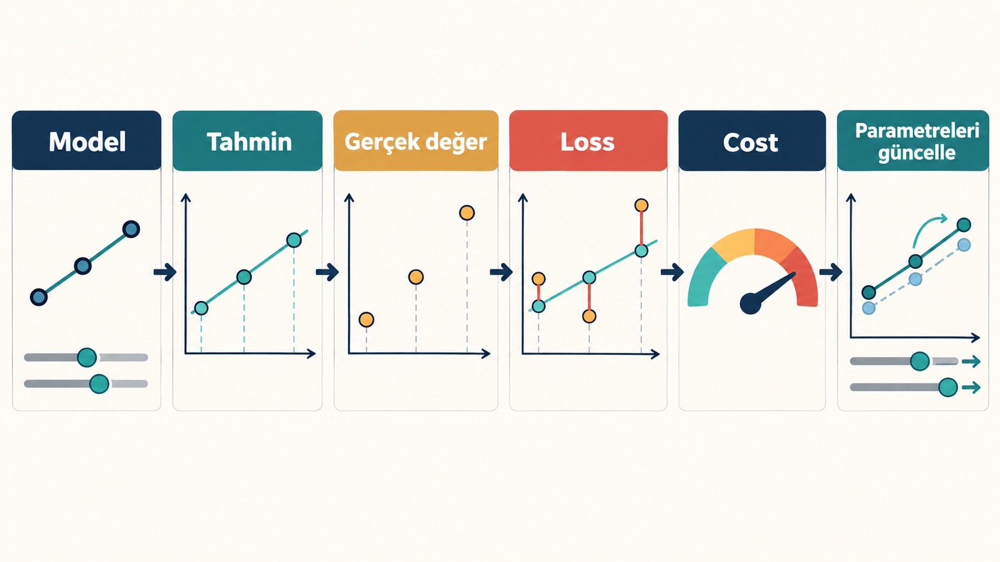

*Gradient descent, parametreleri hangi yönde değiştireceğine bu cost sinyaline bakarak karar verir.*

In [ ]:
# Küçük bir regresyon örneğinde loss ve cost farkını görelim.
import numpy as np
import pandas as pd

actual = np.array([3.0, 5.0, 7.0])
predicted = np.array([2.5, 5.5, 8.0])
error = predicted - actual
loss_per_row = error ** 2
cost = loss_per_row.mean()

cost_example = pd.DataFrame({
    'gerçek': actual,
    'tahmin': predicted,
    'hata': error,
    'satır_loss': loss_per_row,
})
print(cost_example.to_string(index=False))
print('\nBütün veri setinin cost değeri:', round(cost, 3))

## Gradient descent

Gradient descent, çok farklı problemler için optimum sonucu bulabilme yeteneğine sahip bir en iyileme algoritmasıdır. Ana fikir, parametreleri her iterasyonda ayarlayarak maliyet fonksiyonunu en küçültmektir.

Hikayeleştirme: bir dağda yoğun siste kaybolduğunuzu ve sadece ayağınızı bastığınız yerin eğimini hissettiğinizi düşünün. Vadiye hızla ulaşmanın iyi bir yolu en dik eğimi aşağı doğru takip etmektir.

Bu tam olarak *gradient descent*'in yaptığı şeydir: Hata fonksiyonunun Q(teta) parametre vektörüne göre gradyanını hesaplar ve azalan gradyan yönünde ilerler. Gradyan sıfır olduğunda, minimum seviyeye ulaştık demektir.

### Gradient descent'i bir tepe inişi gibi düşünelim

Modelin hatasını bir arazi yüksekliği gibi hayal edelim. Amacımız en düşük noktaya ulaşmak:

1. Rastgele veya sıfır katsayılarla başlarız.
2. Mevcut katsayılarla tahmin yapıp hatayı ölçeriz.
3. Her katsayının hatayı hangi yönde artırdığını kontrol ederiz.
4. Katsayıyı bunun ters yönünde küçük bir adımla değiştiririz.
5. Yeni katsayılarla tekrar tahmin yaparız.

Adım büyüklüğü çok büyükse minimumu geçebilir, çok küçükse öğrenme gereksiz yavaşlar. Aşağıdaki hücre bu güncelleme döngüsünü kütüphane kullanmadan gösteriyor.

### Gradient descent: hata yüzeyinde minimuma ilerlemek

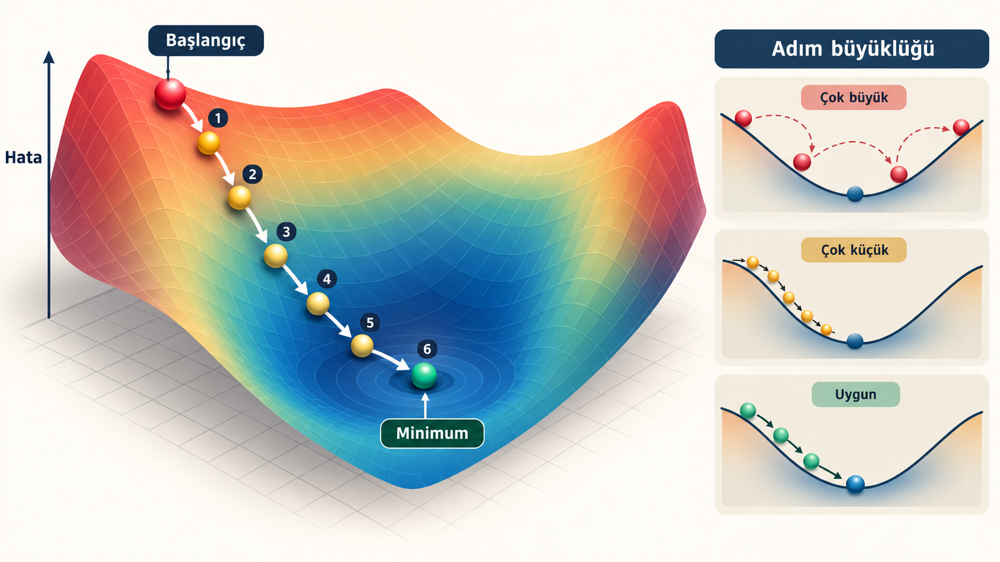

*Her adımda hatanın azaldığı yön bulunur. Çok büyük adım minimumu aşabilir; çok küçük adım öğrenmeyi yavaşlatır.*

In [ ]:
# Lineer regresyonu sklearn kullanmadan gradient descent ile çözüyorum.
import numpy as np

x = np.array([1., 2., 3., 4., 5.])
y = np.array([3.1, 5.0, 7.2, 8.9, 11.1])
X = np.c_[np.ones(len(x)), x]  # bias kolonu + x
beta = np.zeros(2)
learning_rate = 0.03

for _ in range(5_000):
    prediction = X @ beta
    gradient = X.T @ (prediction - y) / len(y)
    beta -= learning_rate * gradient

print(f"Öğrenilen denklem: y = {beta[0]:.3f} + {beta[1]:.3f}x")
print("MSE:", np.mean((X @ beta - y) ** 2).round(4))

## 4. Neden binary hedefe lineer regresyon uygulamıyoruz?

Lineer regresyonun çıktısı sınırsızdır; `-0.3` veya `1.4` gibi değerler üretebilir. Bunları churn olasılığı olarak yorumlayamayız. Binary classification için çıktıyı `0` ile `1` arasına taşıyan bir mekanizmaya ihtiyacımız vardır.

Lojistik regresyon önce lineer bir skor üretir, ardından sigmoid adı verilen S biçimli dönüşümle bu skoru olasılığa çevirir.

## 5. Lojistik regresyon nasıl çalışır?

1. Her feature için bir katsayıyla başlar.
2. Feature değerlerini katsayılarla çarpıp toplar ve lineer bir skor üretir.
3. Sigmoid dönüşümü negatif ve pozitif sınırsız skorları `0–1` aralığına sıkıştırır.
4. Üretilen olasılığı gerçek sınıfla karşılaştırır.
5. Gerçek churn müşterisine düşük olasılık veya gerçek non-churn müşterisine yüksek olasılık verdiğinde cezalandırılır.
6. Katsayıları bu hatayı azaltacak yönde günceller ve döngüyü tekrarlar.

Pozitif katsayı ilgili feature arttıkça churn eğiliminin yükseldiğini, negatif katsayı düştüğünü gösterir. Diğer değişkenler ve veri üretim süreci nedeniyle bunu doğrudan nedensellik olarak yorumlamam.

### Lojistik regresyon: feature'lardan olasılığa

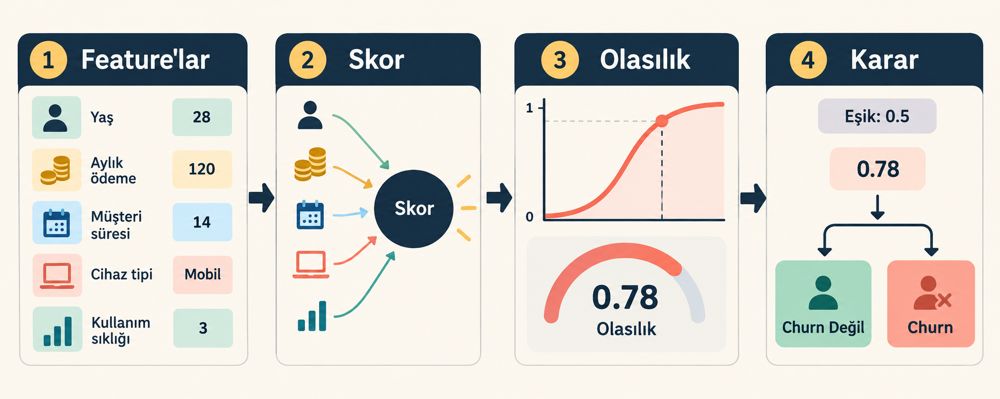

*Feature'lar bir skorda birleşir, sigmoid bu skoru olasılığa dönüştürür ve threshold iş kararını üretir.*

### Log-loss modele ne öğretir?

Sadece doğru veya yanlış sınıfa bakmak öğrenme için yeterli değildir. `0.51` ve `0.99` olasılıkları aynı sınıf kararını verse de modelin güven düzeyi farklıdır. Log-loss bu farkı kullanır:

- Gerçek sınıfa yüksek olasılık verilirse ceza küçülür.
- Gerçek sınıfa düşük olasılık verilirse ceza büyür.
- Özellikle yanlış ve aşırı güvenli tahminler ağır cezalandırılır.
- Model bütün satırlardaki ortalama cezayı azaltacak katsayıları arar.

Aşağıdaki sıfırdan kodda `p - y` farkı, modelin olasılığı hangi yönde düzeltmesi gerektiğini gösterir.

### Log-loss: yanlış ve aşırı güvenli tahmine daha büyük ceza

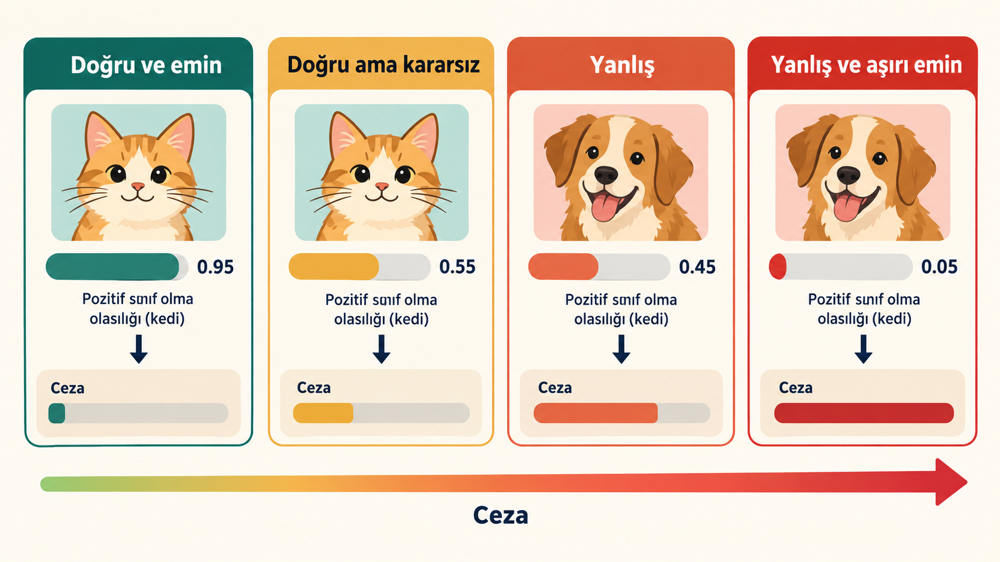

*Model yalnız doğru sınıfı değil, olasılığın ne kadar güvenilir olduğunu da öğrenir. Yanlış ve aşırı emin tahmin en büyük cezayı alır.*

In [ ]:
# Lojistik regresyonu sklearn kullanmadan gradient descent ile kuruyorum.
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

X_log = np.array([
    [1., -2.0], [1., -1.2], [1., -0.7],
    [1.,  0.2], [1.,  0.8], [1.,  1.7],
])
y_log = np.array([0., 0., 0., 0., 1., 1.])
beta_log = np.zeros(X_log.shape[1])

for _ in range(10_000):
    p = sigmoid(X_log @ beta_log)
    gradient = X_log.T @ (p - y_log) / len(y_log)
    beta_log -= 0.05 * gradient

p = sigmoid(X_log @ beta_log)
loss = -np.mean(y_log * np.log(p + 1e-12) + (1-y_log) * np.log(1-p + 1e-12))
print("Katsayılar:", beta_log.round(3))
print("Olasılıklar:", p.round(3))
print("Log-loss:", round(loss, 4))

## 6. Unsupervised learning'e kısa giriş

Unsupervised learning'de hedef değişken $y$ yoktur; yalnızca $X$ vardır. Amaç tahmin edilen bir etiketi öğrenmek değil, verideki yapıyı ortaya çıkarmaktır.

- **Clustering:** Benzer gözlemleri gruplama
- **Dimensionality reduction:** Bilgiyi daha az boyutta temsil etme
- **Anomaly detection:** Genel yapıdan sapmaları bulma

K-means benzer gözlemleri birbirine yakın kümelerde toplamaya çalışır. Algoritma şu adımları tekrarlar:

1. Kaç küme istediğimize karar verir ve başlangıç merkezleri seçer.
2. Her gözlemin bütün merkezlere uzaklığını hesaplar.
3. Gözlemi en yakın merkezin kümesine atar.
4. Her kümenin merkezini o kümeye atanan gözlemlerin ortalamasıyla günceller.
5. Atamalar değişmeyene veya iterasyon sınırına ulaşana kadar devam eder.

Kümeler gerçek sınıflar değildir. `Küme 2 = churn müşterisi` gibi bir yorum, sonradan iş doğrulaması yapılmadan söylenemez.

### K-means: ata, merkezi güncelle, tekrar et

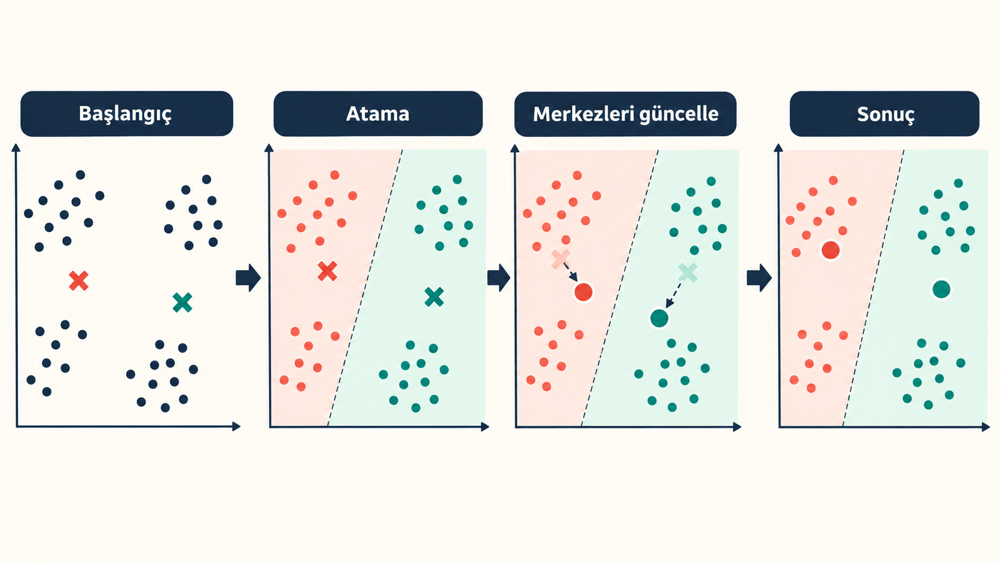

*Noktalar en yakın merkeze atanır; merkezler yeni grupların ortasına taşınır ve atamalar sabitlenene kadar süreç devam eder.*

In [ ]:
# K-means'in tek iterasyonunu sıfırdan görelim.
points = np.array([[1., 1.], [1.5, 2.], [3., 4.], [5., 7.], [3.5, 5.], [4.5, 5.]])
centroids = np.array([[1., 1.], [5., 7.]])
distances = np.linalg.norm(points[:, None, :] - centroids[None, :, :], axis=2)
labels = distances.argmin(axis=1)
new_centroids = np.vstack([points[labels == k].mean(axis=0) for k in range(2)])
print("Atamalar:", labels)
print("Yeni merkezler:\n", new_centroids)

## 7. Decision Tree nasıl öğrenir?

Decision Tree feature uzayını art arda gelen `if/else` kurallarıyla böler:

1. Bütün satırlar kök düğümde başlar.
2. Model her feature için olası eşikleri dener: örneğin `support_calls <= 2.5`.
3. Her aday kuralın veriyi iki gruba ayırdığında sınıfları ne kadar temizlediğini ölçer.
4. Churn ve non-churn örneklerini en iyi ayıran kuralı seçer.
5. Aynı aramayı sol ve sağ çocuk düğümlerde tekrarlar.
6. Derinlik, minimum örnek veya saflık koşuluna ulaştığında büyümeyi durdurur.
7. Yeni müşteri kökten yaprağa kadar kuralları izler; yapraktaki sınıf oranı olasılık olarak kullanılır.

**Gini** ve **entropy**, bir düğümde sınıfların ne kadar karışık olduğunu farklı yollarla ölçer. Tamamı tek sınıf olan düğüm saftır; sınıfların dengeli karıştığı düğüm daha kirlidir.

### Decision Tree: en iyi bölmeyi seçerek ilerlemek

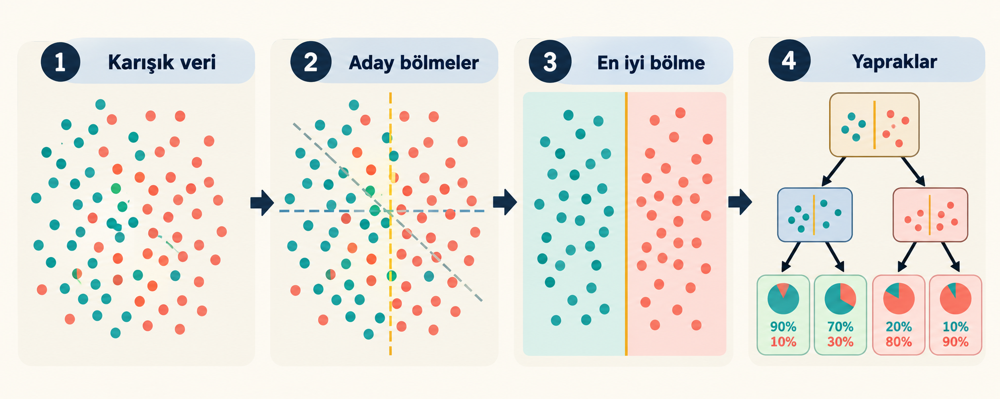

*Ağaç farklı split adaylarını dener, sınıfları en iyi ayıranı seçer ve aynı işlemi çocuk düğümlerde tekrarlar.*

In [ ]:
# Tek bir split'in Gini kazancını sıfırdan hesaplayalım.
def gini(y):
    if len(y) == 0:
        return 0.0
    probabilities = np.bincount(np.asarray(y, dtype=int)) / len(y)
    return 1 - np.sum(probabilities ** 2)

def gini_gain(parent, left, right):
    weighted_children = len(left)/len(parent)*gini(left) + len(right)/len(parent)*gini(right)
    return gini(parent) - weighted_children

parent = np.array([0, 0, 0, 0, 1, 1, 1, 1])
left = np.array([0, 0, 0, 1])
right = np.array([0, 1, 1, 1])
print("Parent Gini:", round(gini(parent), 3))
print("Split kazancı:", round(gini_gain(parent, left, right), 3))

### Regresyon ağacı nasıl farklılaşır?

Regresyon ağacı da aynı `if/else` yapısını kurar; fakat sınıf saflığı yerine sayısal hedeflerin birbirine yakınlığını kullanır:

1. Bir aday eşikle veri iki gruba ayrılır.
2. Her grubun hedef ortalaması hesaplanır.
3. Gruptaki gerçek değerlerin bu ortalamadan ne kadar saptığı ölçülür.
4. Toplam hatayı en fazla azaltan split seçilir.
5. Yeni gözlemin tahmini, ulaştığı yapraktaki eğitim hedeflerinin ortalamasıdır.

Ağaçlar doğrusal olmayan ilişkileri ve etkileşimleri kendileri yakalayabilir; fakat çok derin bir ağaç eğitim verisini ezberleyerek yüksek varyans üretir. `max_depth`, `min_samples_leaf` ve pruning bu nedenle önemlidir.

In [ ]:
# Bir feature için bütün aday eşikleri deneyen küçük split araması.
def best_gini_split(x, y):
    thresholds = (np.sort(np.unique(x))[:-1] + np.sort(np.unique(x))[1:]) / 2
    candidates = []
    for threshold in thresholds:
        left_y, right_y = y[x <= threshold], y[x > threshold]
        gain = gini_gain(y, left_y, right_y)
        candidates.append((threshold, gain, len(left_y), len(right_y)))
    return max(candidates, key=lambda row: row[1])

calls = np.array([0, 1, 1, 2, 3, 4, 5, 6])
churn = np.array([0, 0, 0, 0, 1, 0, 1, 1])
threshold, gain, n_left, n_right = best_gini_split(calls, churn)
print(f"En iyi eşik: support_calls <= {threshold}, gain={gain:.3f}, left={n_left}, right={n_right}")

## Bagging modeli nedir?

Bagging, açılımı **Bootstrap Aggregating** olan bir ensemble yöntemidir. Tek bir modele güvenmek yerine, aynı modelin farklı veri örnekleri üzerinde eğitilmiş birçok versiyonunu oluşturur ve bu modellerin tahminlerini birleştirir.

Adım adım şu şekilde çalışır:

1. Eğitim verisinden rastgele satırlar seçilerek yeni bir veri seti oluşturulur.
2. Seçilen satır tekrar veri havuzuna konduğu için aynı satır birden fazla kez seçilebilir.
3. Bazı satırlar hiç seçilmeyebilir. Bunlara **Out-of-Bag (OOB)** gözlemler denir.
4. Oluşturulan her bootstrap veri seti üzerinde ayrı bir model eğitilir.
5. Bu işlem çok sayıda model oluşturulana kadar tekrarlanır.
6. Sınıflandırmada modellerin oyları veya ürettikleri olasılıklar birleştirilir.
7. Regresyonda modellerin sayısal tahminlerinin ortalaması alınır.

Örneğin beş ağaç bir müşteri için aşağıdaki churn olasılıklarını üretmiş olsun:

```text
Ağaç 1 → 0.72
Ağaç 2 → 0.61
Ağaç 3 → 0.40
Ağaç 4 → 0.83
Ağaç 5 → 0.55
```

Bagging modeli bu tahminlerin ortalamasını alır:

```text
Nihai churn olasılığı → 0.62
```

Eşik değerimiz `0.50` ise müşteri churn sınıfına atanır.

### Bagging bize ne gösterir?

Bagging tek başına özel bir istatistik veya grafik göstermez. Birden fazla modelin ortak görüşünü kullanarak daha kararlı bir tahmin üretir.

Sınıflandırma probleminde genellikle şunları verir:

- Tahmin edilen sınıf
- Her sınıfa ait olasılık
- Modellerin ortak kararı
- Destekleniyorsa Out-of-Bag skoru

Regresyon probleminde ise modellerin tahminlerinin ortalamasını verir.

### Bagging neden kullanılır?

Decision Tree gibi modeller eğitim verisindeki küçük değişikliklere karşı hassastır. Veride birkaç satır değiştiğinde ağacın yapısı ve tahminleri önemli ölçüde değişebilir. Bu duruma yüksek varyans denir.

Bagging, farklı veri örnekleri üzerinde eğitilen çok sayıda ağacın tahminlerini birleştirerek:

- Tek bir ağacın yaptığı uç hataları yumuşatır.
- Modelin varyansını azaltır.
- Tahminleri daha kararlı hale getirir.
- Overfitting riskini azaltabilir.
- Tek bir ağaca göre daha güçlü bir genelleme sağlayabilir.

### Bagging neyi göstermez?

Bagging sonucunu yorumlarken şu ayrımları yapmamız gerekir:

- Bagging yüksek performansı garanti etmez.
- Yanlış hazırlanmış veriyi veya data leakage problemini düzeltmez.
- OOB skoru zaman bazlı test setinin yerine geçmez.
- Tahmin olasılığı bir neden-sonuç ilişkisi göstermez.
- Feature importance, müşterinin neden churn edeceğini tek başına kanıtlamaz.

### Bagging, Random Forest ve Extra Trees ilişkisi

**Bagging Classifier**, seçtiğimiz base modeli farklı bootstrap örneklerinde tekrar tekrar eğitir.

**Random Forest**, bagging yaklaşımına ek olarak her split sırasında feature’ların yalnızca rastgele seçilen bir bölümünü değerlendirir. Böylece ağaçların birbirine benzemesini azaltır.

**Extra Trees** ise feature seçiminin yanında split eşiklerine de daha fazla rastgelelik ekler.

Özetle:

```text
Bagging
→ Farklı bootstrap verileri
→ Birden fazla model
→ Tahminleri birleştirme
→ Daha düşük varyans
→ Daha kararlı sonuç
```

> Bagging’in temel amacı tek bir çok güçlü model oluşturmak değil, farklı modellerin hatalarını birbirine dengeleterek daha güvenilir bir ortak tahmin üretmektir.

## 8. Bagging nasıl çalışır?

Bagging = **Bootstrap Aggregating**. Tek bir kararsız modele güvenmek yerine birçok farklı versiyonunu üretip görüşlerini birleştiririz:

1. Eğitim verisinden, satırları geri koyarak rastgele bir örneklem çekeriz. Bazı satırlar birkaç kez seçilir, bazıları hiç seçilmez.
2. Bu örneklemde bir base model, çoğunlukla Decision Tree, eğitiriz.
3. Aynı işlemi birçok kez tekrarlayarak farklı ağaçlar oluştururuz.
4. Regresyonda ağaç tahminlerinin ortalamasını alırız.
5. Sınıflandırmada çoğunluk oyu veya olasılık ortalaması kullanırız.

Bagging'in temel hedefi tek ağacın veriye aşırı duyarlılığını azaltmaktır. Bir ağacın yaptığı uç hata, diğer ağaçların ortalaması içinde yumuşar.

### Bagging: farklı veri örnekleri, farklı ağaçlar, ortak karar

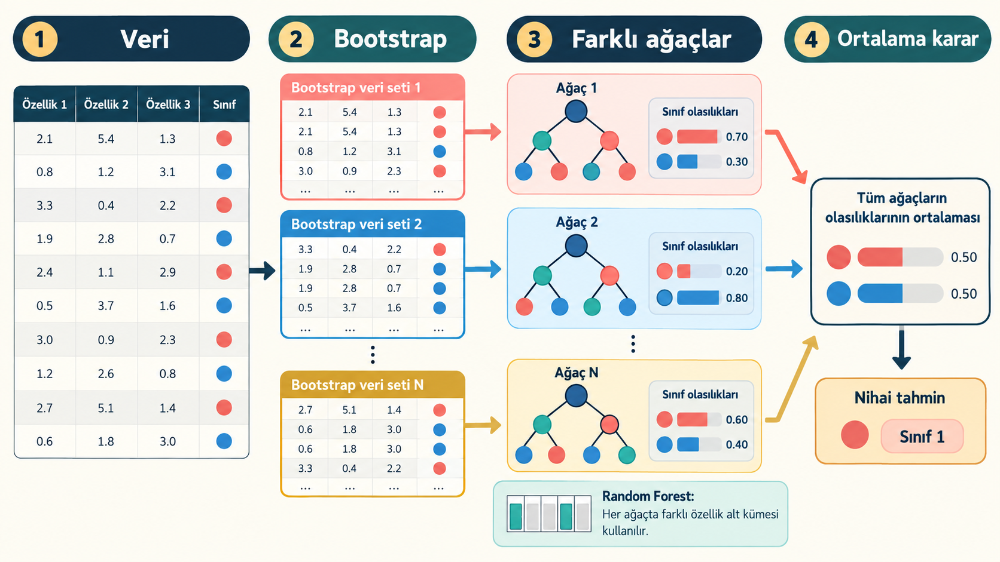

*Bootstrap örneklerinde paralel ağaçlar eğitilir; tahminler ortalanarak tek ağacın oynaklığı azaltılır.*

### Bootstrap ve OOB gözlemler

Bootstrap örneklemede seçtiğimiz satırı havuza geri koyarız. Bu yüzden aynı müşteri birkaç kez seçilebilirken bazı müşteriler hiç seçilmez. Büyük veri setlerinde her ağacın bootstrap örneğinde benzersiz satırların yaklaşık `%63,2`'si bulunur; yaklaşık `%36,8`'i dışarıda kalır.

Dışarıda kalan bu satırlara **out-of-bag (OOB)** gözlemler deriz. Bir ağaç bu satırları eğitimde görmediği için, onlar üzerinde ek bir değerlendirme sinyali üretebiliriz. OOB skorunu yine de zaman bazlı test setinin yerine koymam.

### Ortalama almak varyansı neden düşürür?

Bir sınıftaki tek öğrencinin tahminine değil, birbirinden bağımsız birçok öğrencinin tahmin ortalamasına baktığımızı düşünelim. Bireysel uç hatalar birbirini dengeleyebilir. Bagging de benzer biçimde çalışır.

Ancak bütün ağaçlar birbirine çok benziyorsa aynı hataları yaparlar ve ortalama almak fazla fayda sağlamaz. Random Forest bu nedenle her split'te bütün feature'lara bakmak yerine rastgele bir feature alt kümesini değerlendirir. Amaç ağaçları farklılaştırmak ve hatalarının korelasyonunu azaltmaktır.

In [ ]:
# Bootstrap ve çoğunluk oyunu küçük bir örnekle görelim.
rng = np.random.default_rng(42)
base_indices = np.arange(10)
bootstrap_samples = [rng.choice(base_indices, size=10, replace=True) for _ in range(3)]
for i, sample in enumerate(bootstrap_samples, start=1):
    oob = np.setdiff1d(base_indices, np.unique(sample))
    print(f"Bootstrap {i}: {sample} | OOB: {oob}")

tree_probabilities = np.array([0.72, 0.61, 0.40, 0.83, 0.55])
bagged_probability = tree_probabilities.mean()
print("Ortalama olasılık:", round(bagged_probability, 3))
print("0.5 eşikli karar:", int(bagged_probability >= 0.5))

## 9. Bagging ailesinden örnekler

| Model | Satır rastgeleliği | Feature rastgeleliği | Split rastgeleliği |
|---|---|---|---|
| Bagging + Tree | Bootstrap | İsteğe bağlı | Standart en iyi split |
| Random Forest | Bootstrap | Her split'te feature alt kümesi | Alt kümedeki en iyi split |
| Extra Trees | Genellikle tüm veri / opsiyonel bootstrap | Feature alt kümesi | Rastgele eşikler |
| Random Subspace | Aynı veya bootstrap satırlar | Farklı feature alt kümeleri | Base modele bağlı |

Random Forest ağaç sayısı arttıkça klasik anlamda overfit olmak zorunda değildir; hata çoğunlukla bir seviyede plato yapar. Fakat hesaplama maliyeti büyür ve yanlış validation tasarımını hiçbir ensemble düzeltemez.

# Uygulama — Önceki haftanın churn verisi

Önce 2. haftada oluşturduğumuz temiz dosyayı arayacağım. Notebook tek başına çalıştırılıyorsa aynı veri mantığını yeniden üreteceğim. Böylece harici CSV zorunluluğu olmayacak.

In [ ]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path.cwd() / "course_workspace" / "isp-churn-project" / "data" / "processed" / "customer_snapshot_clean.csv"

def generate_churn_data(n=5_000, seed=42):
    r = np.random.default_rng(seed)
    snapshot = r.choice(pd.to_datetime(["2026-01-31", "2026-02-28", "2026-03-31", "2026-04-30"]), n)
    tenure = np.clip(r.gamma(2.2, 15, n).round(), 1, 120).astype(int)
    contract = r.choice(["monthly", "annual", "two_year"], n, p=[.56, .31, .13])
    city = r.choice(["metro", "large", "small"], n, p=[.45, .35, .20])
    payment = r.choice(["autopay", "card", "transfer"], n, p=[.45, .35, .20])
    fee = np.clip(r.normal(390, 85, n), 150, 750).round(2)
    usage = np.clip(r.gamma(4, 22, n), 2, 400).round(1)
    usage_change = np.clip(r.normal(-2, 22, n), -90, 100).round(1)
    calls = np.clip(r.poisson(1.3, n), 0, 10)
    incidents = np.clip(r.poisson(.7, n), 0, 7)
    late = np.clip(r.poisson(.45, n), 0, 6)
    nps = np.clip(r.normal(7, 2, n).round(), 0, 10)
    modem = np.clip(r.gamma(2.5, 12, n).round(), 1, 96).astype(int)
    logit = -2.5 + .48*(contract=="monthly") - .55*(contract=="two_year") + .24*calls + .31*incidents + .28*late - .02*tenure - .16*nps - .014*usage_change + .002*(fee-350)
    target = r.binomial(1, 1/(1+np.exp(-logit)))
    return pd.DataFrame({"customer_id":[f"C{i:06d}" for i in range(n)], "snapshot_date":snapshot, "tenure_months":tenure, "contract_type":contract, "city_tier":city, "payment_method":payment, "monthly_fee":fee, "avg_usage_gb_30d":usage, "usage_change_90d_pct":usage_change, "support_calls_90d":calls, "network_incidents_30d":incidents, "late_payments_6m":late, "nps_score":nps, "modem_age_months":modem, "nps_missing":0, "churn_30d":target})

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH, parse_dates=["snapshot_date"])
    print("2. hafta verisi yüklendi:", DATA_PATH)
else:
    df = generate_churn_data()
    print("Dosya bulunmadığı için aynı kurallarla sentetik veri üretildi.")

print("Boyut:", df.shape, "| Churn oranı:", round(100*df.churn_30d.mean(), 2), "%")

## 10. Validation: random split yerine zaman ayrımı

Amacım gelecekteki müşterileri tahmin etmek olduğu için Ocak–Mart snapshot'larını train, Nisan snapshot'ını test olarak kullanacağım. `customer_id` kimliktir; feature değildir. `snapshot_date` ise split için kullanılır, modele doğrudan verilmez.

In [ ]:
TARGET = "churn_30d"
ID_COLUMNS = ["customer_id", "snapshot_date"]
FEATURES = [c for c in df.columns if c not in ID_COLUMNS + [TARGET]]
train_mask = df["snapshot_date"] < pd.Timestamp("2026-04-01")
test_mask = ~train_mask
X_train, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, TARGET]
X_test, y_test = df.loc[test_mask, FEATURES], df.loc[test_mask, TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train churn %:", round(100*y_train.mean(), 2), "| Test churn %:", round(100*y_test.mean(), 2))

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in FEATURES if c not in categorical_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])
print("Sayısal:", numeric_features)
print("Kategorik:", categorical_features)

## 11. Baseline ve bagging modellerini karşılaştıralım

Karşılaştırmaya mutlaka basit bir modelle başlıyorum. Dummy modelden daha iyi olmayan karmaşık modelin production değeri yoktur. Aynı preprocessing ve aynı test dönemi bütün modeller için korunacak.

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2_000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=25, class_weight="balanced", random_state=42),
    "Bagging Tree": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=15, class_weight="balanced"), n_estimators=100, bootstrap=True, random_state=42, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=8, min_samples_leaf=10, class_weight="balanced_subsample", random_state=42, n_jobs=-1, oob_score=True),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=42, n_jobs=-1),
}

results, fitted_models = [], {}
for name, estimator in models.items():
    pipeline = Pipeline([("prep", clone(preprocessor)), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability),
        "pr_auc": average_precision_score(y_test, probability),
    })
    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("model").sort_values("pr_auc", ascending=False)
results_df.round(3)

### Sonucu okurken

- Accuracy'nin yüksek olması tek başına yeterli değildir.
- ROC-AUC tüm eşikleri genel olarak sıralar; ağır dengesizlikte PR-AUC daha açıklayıcı olabilir.
- Precision ve recall, seçilen `0.5` eşiğine bağlıdır.
- Test setine bakarak sürekli model/parametre seçersek test setini validation setine dönüştürmüş oluruz.
- Buradaki amaç kazanan ilan etmekten önce değerlendirme disiplinini kurmaktır.

In [ ]:
# Aynı modelin farklı threshold'larda farklı iş davranışı gösterdiğini görelim.
best_name = results_df.index[0]
best_pipeline = fitted_models[best_name]
best_probability = best_pipeline.predict_proba(X_test)[:, 1]
threshold_rows = []
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    pred = (best_probability >= threshold).astype(int)
    threshold_rows.append({"threshold":threshold, "selected_customers":int(pred.sum()), "precision":precision_score(y_test,pred,zero_division=0), "recall":recall_score(y_test,pred,zero_division=0), "f1":f1_score(y_test,pred,zero_division=0)})
print("Model:", best_name)
pd.DataFrame(threshold_rows).round(3)

## 12. OOB skoru ve feature importance

Random Forest içindeki her ağaç kendi OOB örneklerinde tahmin üretebilir. Ancak OOB skorunu zaman bazlı test setinin yerine koymayacağım; bootstrap zaman düzenini korumaz. Ayrıca impurity tabanlı feature importance yüksek kardinalite ve çok sayıda split fırsatı olan feature'lara yanlı olabilir. Permutation importance veya SHAP'i ilerleyen haftalarda daha dikkatli kullanacağız.

In [ ]:
rf_pipeline = fitted_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print("Random Forest OOB accuracy:", round(rf_model.oob_score_, 3))
importance.head(12).to_frame("impurity_importance")

## 13. LazyPredict ile hızlı benchmark

LazyPredict birçok modeli varsayılan ayarlarla hızlıca dener. Bunu **model seçme otoritesi** değil, gözden kaçan adayları görmek için keşif aracı olarak kullanacağım. Zaman split'i, veri sızıntısı, iş metriği, kalibrasyon ve production maliyetini bizim yerimize çözmez.

Aşağıdaki hücre yalnız LazyPredict kuruluysa çalışır. Kurulum: `pip install lazypredict`

In [ ]:
try:
    from lazypredict.Supervised import LazyClassifier

    # LazyPredict'e tamamen sayısal ve aynı preprocessing'den geçmiş matris veriyorum.
    benchmark_preprocessor = clone(preprocessor)
    X_train_ready = benchmark_preprocessor.fit_transform(X_train)
    X_test_ready = benchmark_preprocessor.transform(X_test)
    lazy = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    lazy_models, lazy_predictions = lazy.fit(X_train_ready, X_test_ready, y_train, y_test)
    print(lazy_models.head(10).to_string())
except ImportError:
    print("LazyPredict kurulu değil. `pip install lazypredict` sonrasında bu hücreyi yeniden çalıştırabilirsiniz.")
except Exception as exc:
    print("LazyPredict ortam/paket uyumluluğu nedeniyle çalışmadı:", type(exc).__name__, "-", exc)

# LAB — 60 dakikalık uygulama

## 1. İşleyiş kontrolü (10 dk)
- Verilen küçük sınıf dizisinde hangi düğümün daha saf olduğunu açıklayın.
- İki aday split'ten hangisinin sınıfları daha iyi ayırdığını gerekçelendirin.

## 2. Tek ağaç (10 dk)
- `max_depth` değerini 2, 5 ve sınırsız deneyin.
- Train ve test sonuçları arasındaki farkı yorumlayın.

## 3. Bagging (15 dk)
- Ağaç sayısını 10, 50 ve 250 yapın.
- Tek ağaca göre performans ve çalışma süresini karşılaştırın.

## 4. Random Forest ve Extra Trees (15 dk)
- PR-AUC, recall ve precision değerlerini karşılaştırın.
- Ağaçlar arası korelasyonun neden önemli olduğunu açıklayın.

## 5. Production kararı (10 dk)
- Bir modele ve threshold'a karar verin.
- Seçiminizi performans, karmaşıklık, inference maliyeti ve açıklanabilirlikle savunun.

## 14. Bu haftadan gelecek haftaya

Bu hafta bağımsız veya bootstrap örneklerinde eğitilen modellerin tahminlerini paralel biçimde birleştirdik. Gelecek hafta boosting'de modellerin neden **sıralı** kurulduğunu, her yeni modelin önceki hatalara nasıl odaklandığını ve gradient boosting'in kayıp fonksiyonunu nasıl optimize ettiğini göreceğiz.

### Bagging için şimdilik aklımda kalacak cümle
> Güçlü fakat kararsız ağaçları farklılaştırıp ortalamak, varyansı azaltır.

### Kapanış soruları
1. Lojistik regresyon neden MSE yerine log-loss kullanır?
2. Gini gain bir split'i nasıl değerlendirir?
3. Derin bir ağacın varyansı neden yüksektir?
4. Bootstrap örneğinde neden yaklaşık %36.8 OOB gözlem kalır?
5. Random Forest, standart bagging'e hangi rastgeleliği ekler?
6. Model sayısı büyürken korelasyon neden önemlidir?
7. LazyPredict çıktısındaki birinci modeli doğrudan production'a almak neden doğru değildir?